# Foundations of Vision & Language (FoVL) — Major Assignment
## Multilingual Word Embeddings for Indian Languages

* **Student:** Alok Sahni
* **Roll number:** G25AIT2138
* **Email:** g25ait2138@iitj.ac.in
* **Institution:** Indian Institute of Technology Jodhpur (IITJ)
* **Training corpus:** IndicCorpV2-5k (`rony000013/indiccorpV2-5k`) — the only training data used
* **Evaluation benchmark:** Akhtar et al. (2017), Word Similarity Datasets for Indian Languages (evaluation only)
* **Model:** one monolingual FastText Skip-gram model per language, trained from scratch, exactly 300 dimensions
* **Languages:** Gujarati, Hindi, Marathi, Punjabi, Tamil, Telugu, Urdu

**Rules followed.** No pre-trained embeddings and no external training corpora are used. Every model in this notebook is trained from random initialisation on IndicCorpV2 only. The benchmark's human similarity scores are used only to compute the reported Spearman correlations; they never enter training or model selection.

**How to run (Google Colab).** Runtime → *Run all*. Training is single-threaded with a fixed hash function, so a re-run reproduces the reported numbers exactly. Sections 1–11 produce all results; section 12 builds the submission ZIP after you upload the executed notebook and the report PDF.

## 1. Setup and configuration

In [1]:
%pip -q install "gensim>=4.4" pyarrow

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, sys, re, json, time, gc, zlib, random, zipfile, shutil, unicodedata, urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, rankdata
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import gensim
from gensim.models import FastText

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DIM = 300  # exactly 300, as required

# Training configuration (identical for all languages)
FT_ARGS = dict(
    vector_size=DIM, window=5, min_count=1, sg=1,   # Skip-gram
    min_n=3, max_n=6,                                # character n-grams for OOV words
    epochs=25, seed=SEED,
    negative=5, sample=1e-3, alpha=0.025,            # gensim defaults, written out explicitly
    bucket=2_000_000,                                # n-gram hash buckets (gensim default)
    workers=1,                                       # single thread => bit-for-bit reproducible
)

def stable_hash(text):
    # Deterministic replacement for Python's randomised hash(), used by gensim to seed vectors.
    return zlib.crc32(str(text).encode('utf-8'))

LANGUAGES = {
    'gu': {'name': 'Gujarati', 'file': 'Gujarati-WS.txt'},
    'hi': {'name': 'Hindi',    'file': 'Hindi-WS.txt'},
    'mr': {'name': 'Marathi',  'file': 'Marathi-WS.txt'},
    'pa': {'name': 'Punjabi',  'file': 'Punjabi-WS.txt'},
    'ta': {'name': 'Tamil',    'file': 'Tamil-WS.txt'},
    'te': {'name': 'Telugu',   'file': 'Telugu-WS.txt'},
    'ur': {'name': 'Urdu',     'file': 'Urdu-WS.txt'},
}
NAME_TO_CODE = {v['name'].lower(): k for k, v in LANGUAGES.items()}

ROOT = Path('/content') if Path('/content').exists() else Path.cwd()
OUT = ROOT / 'FOVL_Output'
MODELS_DIR, EMB_DIR, VOC_DIR = OUT / 'models', OUT / 'embeddings', OUT / 'vocabulary'
FIG_DIR, TABLE_DIR = OUT / 'figures', OUT / 'tables'
for d in (OUT, MODELS_DIR, EMB_DIR, VOC_DIR, FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

print('Main hyperparameters:')
print(pd.Series({k: str(v) for k, v in FT_ARGS.items()}, name='value').to_string())
print('Python', sys.version.split()[0], '| NumPy', np.__version__, '| pandas', pd.__version__, '| gensim', gensim.__version__)
print('Output directory:', OUT)

Main hyperparameters:
vector_size        300
window               5
min_count            1
sg                   1
min_n                3
max_n                6
epochs              25
seed                42
negative             5
sample           0.001
alpha            0.025
bucket         2000000
workers              1
Python 3.13.18 | NumPy 2.5.3 | pandas 3.0.5 | gensim 4.4.0
Output directory: /content/FOVL_Output


## 2. Training corpus — IndicCorpV2-5k
The dataset holds 118,243 records across 24 languages; we use the 5,000 records for each of the seven benchmark languages.

In [3]:
PARQUET = ROOT / 'indiccorpV2-5k.parquet'
PARQUET_URL = 'https://huggingface.co/datasets/rony000013/indiccorpV2-5k/resolve/main/data.parquet'
if not PARQUET.exists():
    print('Downloading IndicCorpV2-5k ...')
    urllib.request.urlretrieve(PARQUET_URL, PARQUET)

corpus = pd.read_parquet(PARQUET)
print(f'Total records: {len(corpus):,} across {corpus["language"].nunique()} languages')
TEXTS = {}
for code, cfg in LANGUAGES.items():
    TEXTS[code] = [t for t in corpus.loc[corpus['code'] == code, 'text'] if isinstance(t, str) and t.strip()]
    print(f"  {cfg['name']:<9} ({code}): {len(TEXTS[code]):,} records")
    assert TEXTS[code], f'No training text found for {cfg["name"]}'

Total records: 118,243 across 24 languages
  Gujarati  (gu): 5,000 records
  Hindi     (hi): 5,000 records
  Marathi   (mr): 5,000 records
  Punjabi   (pa): 5,000 records
  Tamil     (ta): 5,000 records
  Telugu    (te): 5,000 records
  Urdu      (ur): 5,000 records


## 3. Word-similarity benchmark (evaluation only)
Every row is kept in its original position, because the exported arrays must preserve the original pair order with shape `(N, 2, 300)`.
The files contain real irregularities that are handled, not repaired: the Hindi file is comma-separated while the others are tab-separated
(the delimiter is detected per line), some files start with a byte-order mark (read as `utf-8-sig`), Marathi has 149 rows without a human score,
and Tamil has one row with a blank word. Rows without a score or with a blank word stay in the arrays but are excluded from the Spearman calculation only.

In [4]:
BENCH_DIR = ROOT / 'Word-Similarity-Datasets-for-Indian-Languages'
BENCH_ZIP = ROOT / 'Word-Similarity-Datasets-for-Indian-Languages-master.zip'
if not BENCH_DIR.exists():
    if BENCH_ZIP.exists():
        with zipfile.ZipFile(BENCH_ZIP) as z:
            BENCH_DIR.mkdir(exist_ok=True)
            for name in z.namelist():
                if name.endswith('-WS.txt'):
                    (BENCH_DIR / Path(name).name).write_bytes(z.read(name))
    else:
        os.system(f'git clone -q https://github.com/syedsarfarazakhtar/Word-Similarity-Datasets-for-Indian-Languages.git "{BENCH_DIR}"')
assert all((BENCH_DIR / cfg['file']).exists() for cfg in LANGUAGES.values()), 'Benchmark files missing'

def nfc(text):
    return unicodedata.normalize('NFC', str(text)).strip()

def load_benchmark(code):
    pairs, scores = [], []
    path = BENCH_DIR / LANGUAGES[code]['file']
    for line in path.read_text(encoding='utf-8-sig', errors='ignore').splitlines():
        if not line.strip():
            continue
        delim = '\t' if '\t' in line else ','
        parts = line.split(delim)
        w1 = nfc(parts[0])
        w2 = nfc(parts[1]) if len(parts) > 1 else ''
        score = np.nan
        if len(parts) > 2 and parts[2].strip():
            try:
                score = float(parts[2].strip())
            except ValueError:
                pass
        pairs.append((w1, w2))
        scores.append(score)
    return pairs, np.asarray(scores, dtype=np.float64)

BENCH = {code: load_benchmark(code) for code in LANGUAGES}
rows = []
for code, (pairs, scores) in BENCH.items():
    valid = sum(bool(a and b) and np.isfinite(s) for (a, b), s in zip(pairs, scores))
    no_score = int(sum(not np.isfinite(s) for s in scores))
    blank = int(sum(not (a and b) for a, b in pairs))
    reason = ', '.join(r for r in ([f'{no_score} without human score'] if no_score else []) +
                       ([f'{blank} with a blank word'] if blank else [])) or '-'
    rows.append({'Language': LANGUAGES[code]['name'], 'Rows (N)': len(pairs), 'Scored rows': valid,
                 'Excluded from rho': len(pairs) - valid, 'Reason': reason})
BENCH_TABLE = pd.DataFrame(rows)
print(BENCH_TABLE.to_string(index=False))
print('All N rows are embedded and exported in order; only the "Scored rows" enter the Spearman correlation.')

Language  Rows (N)  Scored rows  Excluded from rho                  Reason
Gujarati       163          163                  0                       -
   Hindi       235          235                  0                       -
 Marathi       253          104                149 149 without human score
 Punjabi       143          143                  0                       -
   Tamil        97           96                  1     1 with a blank word
  Telugu       111          111                  0                       -
    Urdu       100          100                  0                       -
All N rows are embedded and exported in order; only the "Scored rows" enter the Spearman correlation.


## 4. Preprocessing and tokenisation
Text is Unicode-NFC normalised, split on whitespace, and punctuation (including the danda `।`/`॥`) is stripped from each token.
The same normalisation is applied to benchmark words.

In [5]:
PUNCT = re.compile(r'[।॥,\.!?\'"()\[\]{};:—–\-/\\]')

def tokenize(text):
    tokens = []
    for w in unicodedata.normalize('NFC', str(text)).split():
        w = PUNCT.sub('', w).strip()
        if w:
            tokens.append(w)
    return tokens

print(tokenize('अच्छा छात्र विद्यालय में पढ़ता है।'))

['अच्छा', 'छात्र', 'विद्यालय', 'में', 'पढ़ता', 'है']


## 5. Model training and the OOV resolver
`FastText(...)` creates a **new, randomly initialised** model; nothing is loaded or fine-tuned from external vectors.

**OOV strategy.**
1. In-vocabulary words use their learned vector.
2. Unseen (OOV) words are composed from their learned character 3–6-gram vectors (FastText subword model), which recovers morphology for inflected and compound forms.
3. If a word yields no usable vector (a blank field, or a near-zero subword vector), it falls back to the frequency-weighted mean of the vocabulary vectors, so **every** input gets a finite, non-zero 300-d vector and no word pair is ever discarded.

In [6]:
def train_language(code, overrides=None, save=True):
    sentences = [t for t in (tokenize(x) for x in TEXTS[code]) if t]
    cfg = dict(FT_ARGS)
    if overrides:
        cfg.update(overrides)
    assert cfg['vector_size'] == 300
    t0 = time.time()
    model = FastText(sentences=sentences, hashfxn=stable_hash, **cfg)
    model.hashfxn = hash  # only used to seed initial vectors; reset so saved models load anywhere
    stats = {'Language': LANGUAGES[code]['name'], 'Training records': len(sentences),
             'Tokens': sum(map(len, sentences)), 'Vocabulary': len(model.wv),
             'Epochs': cfg['epochs'], 'Train time (s)': round(time.time() - t0, 1)}
    if save:
        model.save(str(MODELS_DIR / f"{LANGUAGES[code]['name']}_fasttext.model"))
    return model, stats


class WordVectorResolver:
    # FastText vector (in-vocabulary or subword OOV) with a frequency-weighted mean fallback.
    def __init__(self, model):
        assert model.wv.vector_size == 300
        self.kv = model.wv
        self._fallback = None

    def fallback(self):
        if self._fallback is None:
            counts = np.array([self.kv.get_vecattr(w, 'count') for w in self.kv.index_to_key], dtype=np.float64)
            self._fallback = np.average(np.asarray(self.kv.vectors, dtype=np.float64), axis=0, weights=counts).astype(np.float32)
        return self._fallback.copy()

    def vector(self, word):
        word = nfc(word) if isinstance(word, str) else ''
        if word:
            try:
                v = np.asarray(self.kv[word], dtype=np.float32)
                if v.shape == (300,) and np.isfinite(v).all() and np.linalg.norm(v) > 1e-8:
                    return v
            except KeyError:
                pass
        return self.fallback()

    def in_vocab(self, word):
        return nfc(word) in self.kv.key_to_index


def cosine(a, b):
    a = np.asarray(a, dtype=np.float64); b = np.asarray(b, dtype=np.float64)
    d = np.linalg.norm(a) * np.linalg.norm(b)
    return float(a @ b / d) if d > 0 else 0.0


def evaluate(code, model):
    resolver = WordVectorResolver(model)
    pairs, human = BENCH[code]
    arr = np.empty((len(pairs), 2, DIM), dtype=np.float32)
    sims = np.empty(len(pairs), dtype=np.float64)
    for i, (w1, w2) in enumerate(pairs):
        arr[i, 0], arr[i, 1] = resolver.vector(w1), resolver.vector(w2)
        sims[i] = cosine(arr[i, 0], arr[i, 1])
    valid = np.array([bool(a and b) and np.isfinite(h) for (a, b), h in zip(pairs, human)])
    rho, p = spearmanr(human[valid], sims[valid])
    words = sorted({w for pair in pairs for w in pair if w})
    in_vocab = sum(resolver.in_vocab(w) for w in words)
    result = {'Language': LANGUAGES[code]['name'], 'N': len(pairs), 'Scored pairs': int(valid.sum()),
              'Spearman': float(rho), 'p-value': float(p), 'Unique words': len(words),
              'In vocabulary': in_vocab, 'OOV': len(words) - in_vocab,
              'Coverage': in_vocab / len(words), 'OOV rate': 1 - in_vocab / len(words)}
    return result, arr, sims, valid, resolver

print('Training and evaluation functions ready.')

Training and evaluation functions ready.


## 6. Training (from scratch), evaluation and export
For each language: train, compute cosine similarity for every benchmark pair, Spearman's ρ on the scored pairs, vocabulary coverage, and export
* `embeddings/<Language>.npy` — float32 array of shape `(N, 2, 300)` in the original pair order,
* `vocabulary/<Language>_vocab.json` — maps every benchmark word to its `[row, column]` positions in the `.npy` file, with in-vocabulary/OOV status,
* `tables/<Language>_pair_predictions.csv` — human score, cosine similarity and validity flag for every pair.

In [7]:
def export(code, model, arr, sims, valid, resolver):
    name = LANGUAGES[code]['name']
    pairs, human = BENCH[code]
    assert arr.shape == (len(pairs), 2, 300) and arr.dtype == np.float32
    assert np.isfinite(arr).all() and (np.linalg.norm(arr, axis=2) > 1e-8).all()
    np.save(EMB_DIR / f'{name}.npy', arr)
    positions = {}
    for i, (a, b) in enumerate(pairs):
        positions.setdefault(a, []).append([i, 0])
        positions.setdefault(b, []).append([i, 1])
    vocab = {'language': name, 'code': code, 'embedding_file': f'{name}.npy', 'shape': [len(pairs), 2, 300],
             'pair_order': [[a, b] for a, b in pairs],
             'words': {w: {'positions': pos, 'in_vocabulary': bool(w) and resolver.in_vocab(w),
                           'representation': ('learned vector' if w and resolver.in_vocab(w) else
                                              'subword composition' if w else 'fallback mean (blank field)')}
                       for w, pos in positions.items()}}
    (VOC_DIR / f'{name}_vocab.json').write_text(json.dumps(vocab, ensure_ascii=False, indent=1), encoding='utf-8')
    pd.DataFrame({'row': range(len(pairs)), 'word_1': [a for a, _ in pairs], 'word_2': [b for _, b in pairs],
                  'human_score': human, 'cosine_similarity': sims, 'valid_for_spearman': valid}
                 ).to_csv(TABLE_DIR / f'{name}_pair_predictions.csv', index=False, encoding='utf-8-sig')

RESULTS, TRAIN_STATS = [], []
for code, cfg in LANGUAGES.items():
    print(f"Training {cfg['name']} from scratch ...", end=' ', flush=True)
    model, stats = train_language(code)
    result, arr, sims, valid, resolver = evaluate(code, model)
    export(code, model, arr, sims, valid, resolver)
    RESULTS.append(result); TRAIN_STATS.append(stats)
    print(f"{stats['Train time (s)']}s | vocab {stats['Vocabulary']:,} | rho = {result['Spearman']:.4f} | coverage {result['Coverage']:.1%}")
    del model, resolver; gc.collect()

MACRO = float(np.mean([r['Spearman'] for r in RESULTS]))
results_df = pd.DataFrame(RESULTS)
results_df.to_csv(TABLE_DIR / 'language_results.csv', index=False)
pd.DataFrame(TRAIN_STATS).to_csv(TABLE_DIR / 'training_statistics.csv', index=False)
(TABLE_DIR / 'results.json').write_text(json.dumps({'macro_average_spearman': MACRO, 'languages': RESULTS,
    'training': TRAIN_STATS, 'config': {k: v for k, v in FT_ARGS.items()}}, indent=2), encoding='utf-8')

print()
print(results_df[['Language', 'N', 'Scored pairs', 'Spearman', 'p-value']].to_string(index=False, float_format=lambda x: f'{x:.6f}'))
print(f'\nFINAL MACRO-AVERAGE SPEARMAN: {MACRO:.6f}')

Training Gujarati from scratch ... 

111.5s | vocab 41,355 | rho = 0.4484 | coverage 89.6%
Training Hindi from scratch ... 

112.8s | vocab 27,476 | rho = 0.3009 | coverage 87.7%
Training Marathi from scratch ... 

128.1s | vocab 47,657 | rho = 0.2414 | coverage 79.8%
Training Punjabi from scratch ... 

105.4s | vocab 28,777 | rho = 0.4043 | coverage 89.3%
Training Tamil from scratch ... 

130.0s | vocab 58,128 | rho = 0.3204 | coverage 82.4%
Training Telugu from scratch ... 

113.4s | vocab 49,794 | rho = 0.2453 | coverage 72.5%
Training Urdu from scratch ... 

139.7s | vocab 37,758 | rho = 0.3101 | coverage 82.9%

Language   N  Scored pairs  Spearman  p-value
Gujarati 163           163  0.448424 0.000000
   Hindi 235           235  0.300943 0.000003
 Marathi 253           104  0.241377 0.013570
 Punjabi 143           143  0.404259 0.000001
   Tamil  97            96  0.320438 0.001458
  Telugu 111           111  0.245291 0.009464
    Urdu 100           100  0.310145 0.001688

FINAL MACRO-AVERAGE SPEARMAN: 0.324411


## 7. Vocabulary coverage and OOV statistics

In [8]:
cov = results_df[['Language', 'Unique words', 'In vocabulary', 'OOV', 'Coverage', 'OOV rate']].copy()
tot = cov[['Unique words', 'In vocabulary', 'OOV']].sum()
cov.loc[len(cov)] = ['Total', tot['Unique words'], tot['In vocabulary'], tot['OOV'],
                     tot['In vocabulary'] / tot['Unique words'], tot['OOV'] / tot['Unique words']]
cov.to_csv(TABLE_DIR / 'coverage_oov.csv', index=False)
print(cov.to_string(index=False, formatters={'Coverage': '{:.1%}'.format, 'OOV rate': '{:.1%}'.format}))
print()
print(pd.DataFrame(TRAIN_STATS).to_string(index=False))

Language  Unique words  In vocabulary  OOV Coverage OOV rate
Gujarati           221            198   23    89.6%    10.4%
   Hindi           318            279   39    87.7%    12.3%
 Marathi           337            269   68    79.8%    20.2%
 Punjabi           206            184   22    89.3%    10.7%
   Tamil           136            112   24    82.4%    17.6%
  Telugu           160            116   44    72.5%    27.5%
    Urdu           146            121   25    82.9%    17.1%
   Total          1524           1279  245    83.9%    16.1%

Language  Training records  Tokens  Vocabulary  Epochs  Train time (s)
Gujarati              5000  203449       41355      25           111.5
   Hindi              5000  284598       27476      25           112.8
 Marathi              5000  206264       47657      25           128.1
 Punjabi              5000  272700       28777      25           105.4
   Tamil              5000  168026       58128      25           130.0
  Telugu              50

## 8. t-SNE visualisation — 100 words per language
The 100 most frequent vocabulary words of each model are projected from 300 to 2 dimensions (t-SNE is used only for this figure).
Points carry numeric IDs because Matplotlib lacks fonts for all six scripts; `figures/tsne_<Language>_word_labels.csv` maps IDs to words.

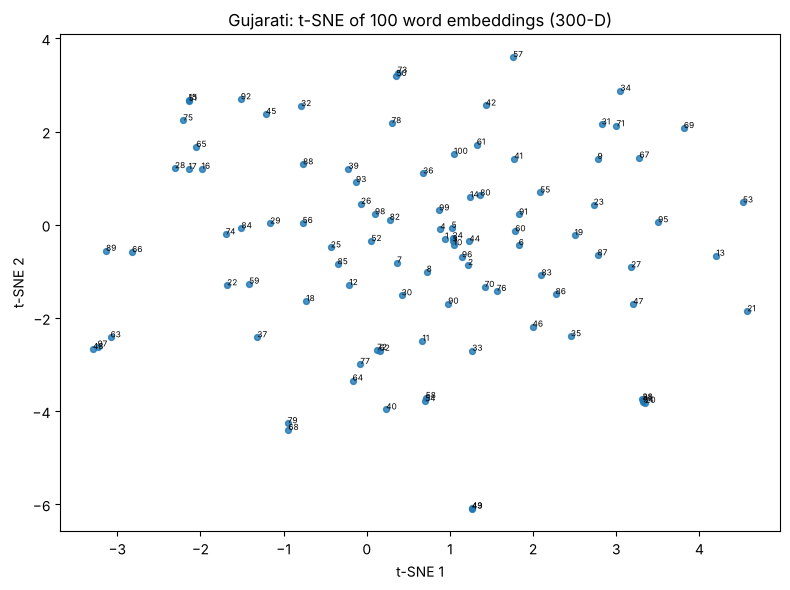

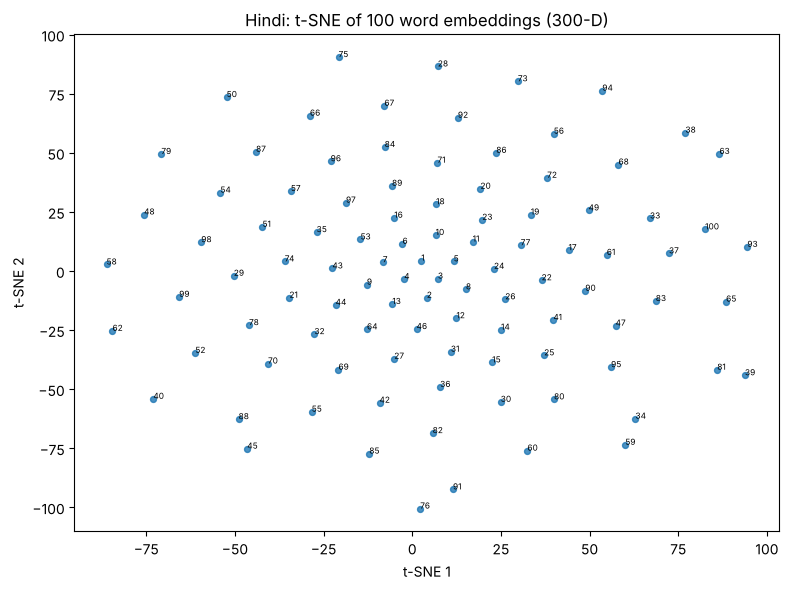

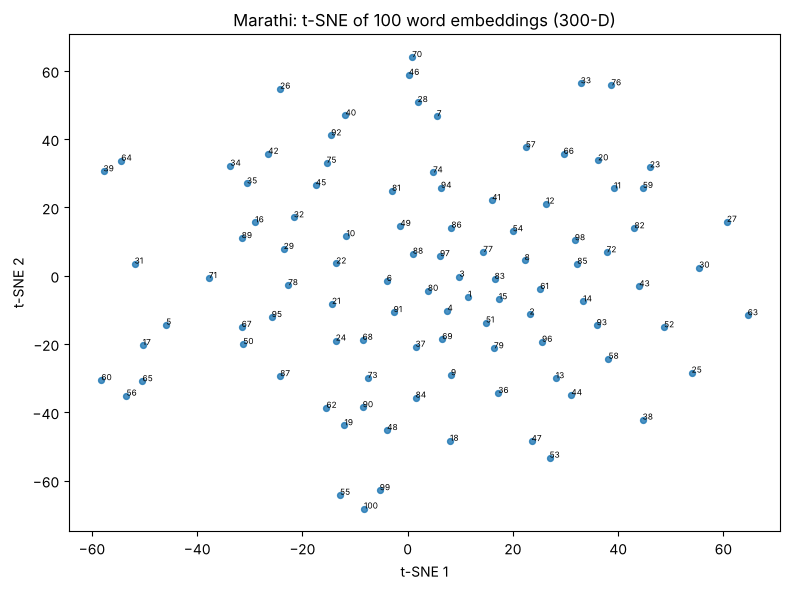

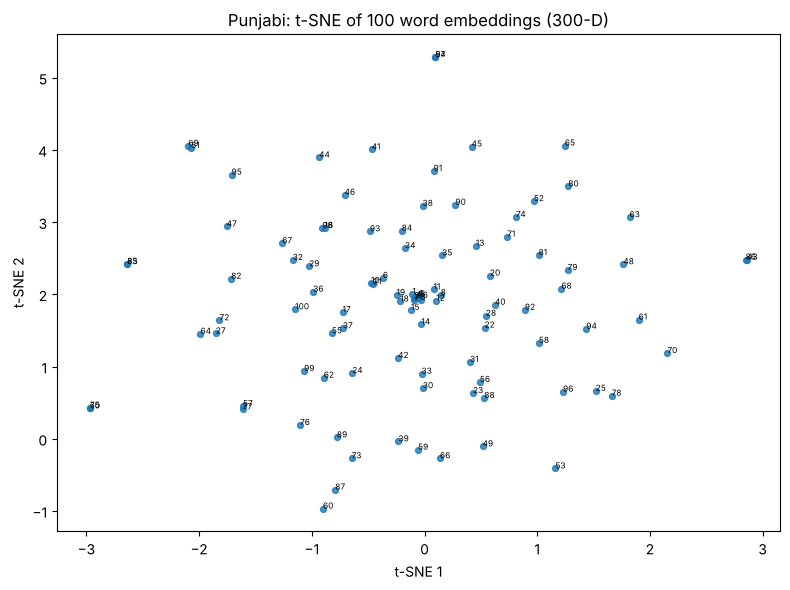

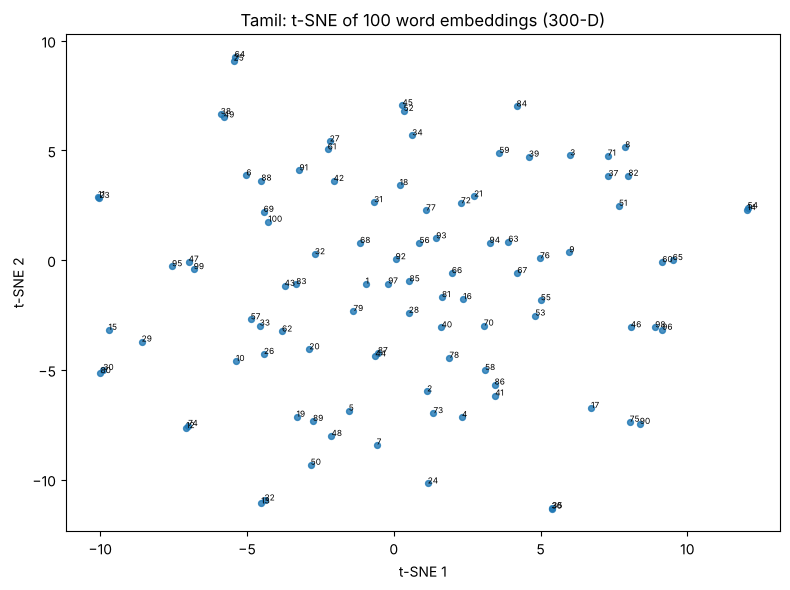

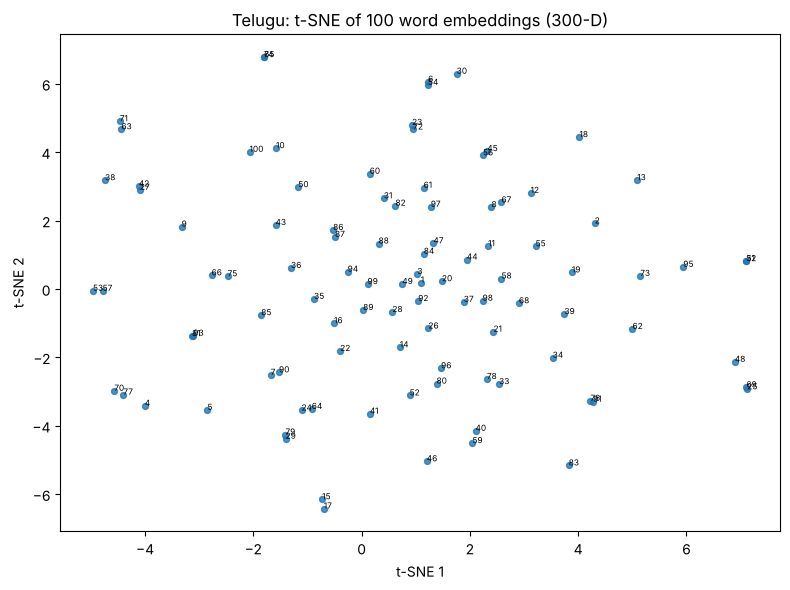

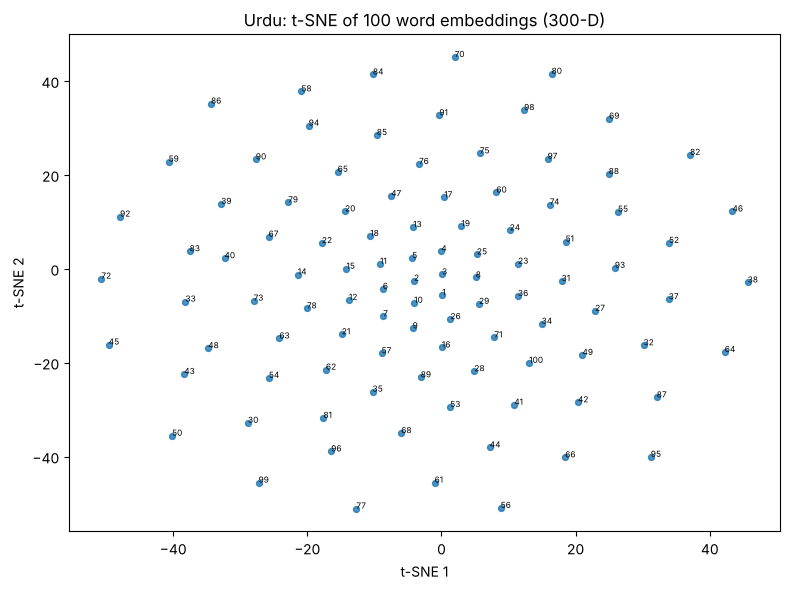

Saved 7 t-SNE figures and 7 word-label files.


In [9]:
for code, cfg in LANGUAGES.items():
    name = cfg['name']
    model = FastText.load(str(MODELS_DIR / f'{name}_fasttext.model'))
    words = model.wv.index_to_key[:100]
    assert len(words) == 100
    xy = TSNE(n_components=2, perplexity=25, init='pca', learning_rate='auto', random_state=SEED).fit_transform(
        np.stack([model.wv[w] for w in words]))
    fig, ax = plt.subplots(figsize=(8, 6))
    ax.scatter(xy[:, 0], xy[:, 1], s=18, alpha=0.8)
    for i, (x, y) in enumerate(xy):
        ax.annotate(str(i + 1), (x, y), fontsize=6)
    ax.set_title(f'{name}: t-SNE of 100 word embeddings (300-D)')
    ax.set_xlabel('t-SNE 1'); ax.set_ylabel('t-SNE 2')
    fig.tight_layout(); fig.savefig(FIG_DIR / f'tsne_{name}.png', dpi=170); plt.show(); plt.close(fig)
    pd.DataFrame({'id': range(1, 101), 'word': words, 'x': xy[:, 0], 'y': xy[:, 1]}).to_csv(
        FIG_DIR / f'tsne_{name}_word_labels.csv', index=False, encoding='utf-8-sig')
    del model; gc.collect()
print('Saved 7 t-SNE figures and 7 word-label files.')

## 9. Word-pair analysis (correctly and incorrectly predicted similarities)
Human scores (1–10) and cosine similarities ([−1, 1]) are on different scales, so pairs are compared by **rank**.
For each language we show the pair whose model rank is closest to the human rank (correct) and the one furthest from it (incorrect); the first five of each are kept (10 examples).

In [10]:
analysis = []
for code, cfg in LANGUAGES.items():
    df = pd.read_csv(TABLE_DIR / f"{cfg['name']}_pair_predictions.csv")
    df = df[df['valid_for_spearman'] == True].copy()
    df['human_rank'] = rankdata(-df['human_score'])
    df['model_rank'] = rankdata(-df['cosine_similarity'])
    df['rank_error'] = np.abs(df['human_rank'] - df['model_rank'])
    for label, part in (('correct', df.nsmallest(1, 'rank_error')), ('incorrect', df.nlargest(1, 'rank_error'))):
        r = part.iloc[0]
        analysis.append({'language': cfg['name'], 'prediction': label, 'word_1': r['word_1'], 'word_2': r['word_2'],
                         'human_score': r['human_score'], 'cosine_similarity': round(r['cosine_similarity'], 4),
                         'human_rank': r['human_rank'], 'model_rank': r['model_rank'], 'rank_error': r['rank_error'],
                         'scored_pairs': len(df)})
analysis = pd.DataFrame(analysis)
selected = pd.concat([analysis[analysis.prediction == 'correct'].head(5),
                      analysis[analysis.prediction == 'incorrect'].head(5)], ignore_index=True)
selected.to_csv(TABLE_DIR / 'word_pair_analysis_10.csv', index=False, encoding='utf-8-sig')
print(selected.to_string(index=False))

language prediction   word_1    word_2  human_score  cosine_similarity  human_rank  model_rank  rank_error  scored_pairs
Gujarati    correct      વાઘ       વાઘ       10.000             1.0000         1.0         1.0         0.0           163
   Hindi    correct कंप्यूटर सॉफ्टवेयर        8.800             0.7361         4.0         4.0         0.0           235
 Marathi    correct      वाघ       वाघ       10.000             1.0000         1.0         1.0         0.0           104
 Punjabi    correct    ਟਾਈਗਰ     ਜਗੁਆਰ        8.375             0.6920        10.0        10.0         0.0           143
   Tamil    correct   ரொட்டி  வெண்ணெய்        7.500             0.4396        32.0        32.0         0.0            96
Gujarati  incorrect    વિલંબ   જાતિવાદ        0.000             0.5943       159.5        34.0       125.5           163
   Hindi  incorrect   समाचार   रिपोर्ट        7.800             0.2083        31.0       224.0       193.0           235
 Marathi  incorrect  टेलिफोन    

## 10. Experiments
All models below are trained from scratch on IndicCorpV2 only, at 300 dimensions, and evaluated on all seven languages.
Benchmark scores are only read off afterwards; they are never used for training or for choosing settings.

* **10.1 Ablation:** change **one** setting of the main configuration at a time.
* **10.2 Word2Vec baseline:** the same Skip-gram setup without subwords, to measure what character n-grams contribute (OOV words get the fallback vector).
* **10.3 Seed robustness:** the main configuration retrained with different random seeds, reported as mean ± standard deviation.

These experiments retrain many models, so they take several times longer than section 6. The next cell prints an estimate from the section 6 timings;
set any of the switches to `False` to skip a group.

In [11]:
RUN_ABLATION, RUN_WORD2VEC, RUN_SEEDS = True, True, True
ABLATIONS = {
    'E2 char n-grams 2-5': {'min_n': 2, 'max_n': 5},
    'E3 15 epochs':        {'epochs': 15},
    'E4 min_count 2':      {'min_count': 2},
}
EXTRA_SEEDS = [1, 7]

main_time = sum(s['Train time (s)'] for s in TRAIN_STATS)
est = main_time * ((len(ABLATIONS) if RUN_ABLATION else 0) + (len(EXTRA_SEEDS) if RUN_SEEDS else 0) + (0.3 if RUN_WORD2VEC else 0))
print(f'Section 6 training took {main_time/60:.1f} min; estimated time for section 10: about {est/60:.0f} min')

Section 6 training took 14.0 min; estimated time for section 10: about 74 min


In [12]:
# 10.1 Ablation on all seven languages
main_rho = dict(zip(results_df['Language'], results_df['Spearman']))
abl_rows = [{'Experiment': 'E1 main configuration', 'Language': n, 'Spearman': r} for n, r in main_rho.items()]
if RUN_ABLATION:
    for exp, overrides in ABLATIONS.items():
        for code, cfg in LANGUAGES.items():
            model, _ = train_language(code, overrides, save=False)
            rho = evaluate(code, model)[0]['Spearman']
            del model; gc.collect()
            abl_rows.append({'Experiment': exp, 'Language': cfg['name'], 'Spearman': rho})
        print(f'{exp}: done')
ablation = pd.DataFrame(abl_rows).pivot(index='Experiment', columns='Language', values='Spearman')
ablation = ablation[[c['name'] for c in LANGUAGES.values()]]
ablation['Macro'] = ablation.mean(axis=1)
ablation.round(6).to_csv(TABLE_DIR / 'experiments_ablation.csv')
print(ablation.round(4).to_string())

E2 char n-grams 2-5: done


E3 15 epochs: done


E4 min_count 2: done
Language               Gujarati   Hindi  Marathi  Punjabi   Tamil  Telugu    Urdu   Macro
Experiment                                                                               
E1 main configuration    0.4484  0.3009   0.2414   0.4043  0.3204  0.2453  0.3101  0.3244
E2 char n-grams 2-5      0.3964  0.3226   0.1743   0.2818  0.2421  0.2331  0.2239  0.2677
E3 15 epochs             0.3622  0.2313   0.1927   0.3907  0.3383  0.2396  0.2371  0.2846
E4 min_count 2           0.4284  0.2726   0.2198   0.3520  0.2873  0.2852  0.3016  0.3067


In [13]:
# 10.2 Word2Vec Skip-gram baseline (no subwords)
from gensim.models import Word2Vec
w2v_rows = []
if RUN_WORD2VEC:
    for code, cfg in LANGUAGES.items():
        sentences = [t for t in (tokenize(x) for x in TEXTS[code]) if t]
        w2v_args = {k: v for k, v in FT_ARGS.items() if k not in ('min_n', 'max_n', 'bucket')}
        model = Word2Vec(sentences=sentences, hashfxn=stable_hash, **w2v_args)
        model.hashfxn = hash
        r = evaluate(code, model)[0]   # OOV words -> fallback mean vector (Word2Vec has no subwords)
        w2v_rows.append({'Language': cfg['name'], 'Word2Vec rho': r['Spearman'], 'FastText rho': main_rho[cfg['name']],
                         'OOV rate': r['OOV rate']})
        del model; gc.collect()
    w2v = pd.DataFrame(w2v_rows)
    w2v.loc[len(w2v)] = ['Macro', w2v['Word2Vec rho'].mean(), w2v['FastText rho'].mean(), np.nan]
    w2v['Gain from subwords'] = w2v['FastText rho'] - w2v['Word2Vec rho']
    w2v.round(6).to_csv(TABLE_DIR / 'experiments_word2vec.csv', index=False)
    print(w2v.round(4).to_string(index=False))

Language  Word2Vec rho  FastText rho  OOV rate  Gain from subwords
Gujarati        0.3966        0.4484    0.1041              0.0518
   Hindi        0.2548        0.3009    0.1226              0.0462
 Marathi        0.1307        0.2414    0.2018              0.1106
 Punjabi        0.2270        0.4043    0.1068              0.1772
   Tamil        0.2154        0.3204    0.1765              0.1051
  Telugu        0.2560        0.2453    0.2750             -0.0107
    Urdu        0.1937        0.3101    0.1712              0.1165
   Macro        0.2392        0.3244       NaN              0.0852


In [14]:
# 10.3 Seed robustness of the main configuration
seed_rows = [{'Seed': SEED, 'Language': n, 'Spearman': r} for n, r in main_rho.items()]
if RUN_SEEDS:
    for seed in EXTRA_SEEDS:
        for code, cfg in LANGUAGES.items():
            model, _ = train_language(code, {'seed': seed}, save=False)
            seed_rows.append({'Seed': seed, 'Language': cfg['name'], 'Spearman': evaluate(code, model)[0]['Spearman']})
            del model; gc.collect()
        print(f'seed {seed}: done')
seeds = pd.DataFrame(seed_rows).pivot(index='Seed', columns='Language', values='Spearman')
seeds = seeds[[c['name'] for c in LANGUAGES.values()]]
seeds['Macro'] = seeds.mean(axis=1)
summary = pd.DataFrame({'Mean': seeds.mean(), 'Std': seeds.std(ddof=1)})
seeds.round(6).to_csv(TABLE_DIR / 'experiments_seeds.csv')
summary.round(6).to_csv(TABLE_DIR / 'experiments_seeds_summary.csv')
print(seeds.round(4).to_string()); print(); print(summary.round(4).to_string())

seed 1: done


seed 7: done
Language  Gujarati   Hindi  Marathi  Punjabi   Tamil  Telugu    Urdu   Macro
Seed                                                                        
1           0.4481  0.3015   0.2562   0.3954  0.3166  0.2716  0.3516  0.3344
7           0.4533  0.2920   0.2308   0.3839  0.3250  0.2706  0.3098  0.3236
42          0.4484  0.3009   0.2414   0.4043  0.3204  0.2453  0.3101  0.3244

            Mean     Std
Language                
Gujarati  0.4499  0.0029
Hindi     0.2981  0.0053
Marathi   0.2428  0.0128
Punjabi   0.3945  0.0102
Tamil     0.3207  0.0042
Telugu    0.2625  0.0149
Urdu      0.3238  0.0240
Macro     0.3275  0.0060


## 11. Inference for arbitrary words (including OOV) — for the private evaluation
These functions load the **saved trained models** and need neither retraining nor benchmark scores.
`get_word_vector` returns a `(300,)` vector, `embed_words` returns `(M, 300)`, `embed_pairs` returns `(N, 2, 300)` in input order,
and `predict_similarity` returns cosine similarities. Languages can be given as a code (`'hi'`) or a name (`'Hindi'`).

In [15]:
_MODELS = {}

def _code(language):
    key = str(language).strip().lower()
    code = key if key in LANGUAGES else NAME_TO_CODE.get(key)
    if code is None:
        raise ValueError(f'Unknown language: {language}')
    return code

def load_language_model(language, models_dir=MODELS_DIR):
    code = _code(language)
    if code not in _MODELS:
        _MODELS.clear(); gc.collect()   # keep one ~2.4 GB model in memory at a time
        path = Path(models_dir) / f"{LANGUAGES[code]['name']}_fasttext.model"
        if path.exists():
            model = FastText.load(str(path), mmap='r')
        else:
            # Models are ~2.4 GB each and are not shipped in the ZIP. Training is deterministic,
            # so retraining from IndicCorpV2 reproduces exactly the same vectors.
            print(f"{path.name} not found: retraining {LANGUAGES[code]['name']} from IndicCorpV2 (deterministic) ...")
            model, _ = train_language(code)
        assert model.wv.vector_size == 300
        _MODELS[code] = WordVectorResolver(model)
    return _MODELS[code]

def get_word_vector(word, language, models_dir=MODELS_DIR):
    return load_language_model(language, models_dir).vector(word)

def embed_words(words, language, models_dir=MODELS_DIR):
    r = load_language_model(language, models_dir)
    return np.stack([r.vector(w) for w in words]).astype(np.float32) if len(words) else np.empty((0, 300), np.float32)

def embed_pairs(pairs, language, models_dir=MODELS_DIR):
    r = load_language_model(language, models_dir)
    out = np.empty((len(pairs), 2, 300), dtype=np.float32)
    for i, (a, b) in enumerate(pairs):
        out[i, 0], out[i, 1] = r.vector(a), r.vector(b)
    return out

def predict_similarity(pairs, language, models_dir=MODELS_DIR):
    return np.array([cosine(a, b) for a, b in embed_pairs(pairs, language, models_dir)])

# Unseen compounds in every language
for word, lang in [('अभिनवपरिवर्तन', 'hi'), ('મનોચિકિત્સાલય', 'gu'), ('तंत्रज्ञानविकास', 'mr'), ('ਵਿਗਿਆਨਿਕਤਾ', 'pa'),
                   ('செயற்கைநுண்ணறிவு', 'ta'), ('కృత్రిమమేధస్సు', 'te'), ('مصنوعی_ذہانت', 'ur')]:
    v = get_word_vector(word, lang)
    print(f'[{lang}] {word}: shape {v.shape}, norm {np.linalg.norm(v):.3f}, in vocabulary: {load_language_model(lang).in_vocab(word)}')

# Hindi: synonyms, an inflected OOV plural, and a malformed string
demo = [('विद्यालय', 'स्कूल'), ('विद्यालयों', 'विद्यालय'), ('क्ष्यज्ञत्रक', 'विद्यालय')]
print('\nPairs shape:', embed_pairs(demo, 'Hindi').shape)
for (a, b), s in zip(demo, predict_similarity(demo, 'Hindi')):
    print(f'{a} / {b}: cosine {s:.4f} (in vocabulary: {load_language_model("hi").in_vocab(a)}, {load_language_model("hi").in_vocab(b)})')
print('Blank input ->', np.linalg.norm(get_word_vector('', 'ta')).round(3), '(fallback vector, never zero)')

[hi] अभिनवपरिवर्तन: shape (300,), norm 2.629, in vocabulary: False


[gu] મનોચિકિત્સાલય: shape (300,), norm 2.086, in vocabulary: False


[mr] तंत्रज्ञानविकास: shape (300,), norm 3.888, in vocabulary: False


[pa] ਵਿਗਿਆਨਿਕਤਾ: shape (300,), norm 3.482, in vocabulary: False


[ta] செயற்கைநுண்ணறிவு: shape (300,), norm 3.386, in vocabulary: False


[te] కృత్రిమమేధస్సు: shape (300,), norm 2.403, in vocabulary: False


[ur] مصنوعی_ذہانت: shape (300,), norm 2.049, in vocabulary: False



Pairs shape: (3, 2, 300)
विद्यालय / स्कूल: cosine 0.5637 (in vocabulary: True, True)
विद्यालयों / विद्यालय: cosine 0.9039 (in vocabulary: True, True)
क्ष्यज्ञत्रक / विद्यालय: cosine 0.5708 (in vocabulary: False, True)


Blank input -> 3.531 (fallback vector, never zero)


## 12. Submission package (ZIP)
1. **File → Download → Download .ipynb** to save this executed notebook.
2. Run the next cell and upload **two files**: the downloaded notebook and `Experimental_Report.pdf`.
3. Run the cell after it: it validates every artifact and writes `/content/FOVL_Word_Embeddings_Submission.zip`.

The ZIP contains the `.npy` embeddings, vocabulary mappings, figures, result tables, this notebook and the report.
The trained FastText models (about 2.4 GB each because of FastText's default 2 million n-gram buckets) are kept in `FOVL_Output/models/`
but not zipped; section 11 retrains any missing model deterministically, giving identical vectors.

In [ ]:
NOTEBOOK_NAME = 'FOVL_Word_Embeddings_G25AIT2138.ipynb'
REPORT_NAME = 'Experimental_Report.pdf'
try:
    from google.colab import files
    for name in files.upload():
        target = OUT / (REPORT_NAME if name.lower().endswith('.pdf') else NOTEBOOK_NAME)
        shutil.move(name, target)
        print('Saved', target)
except ImportError:
    print('Not running in Colab: place', NOTEBOOK_NAME, 'and', REPORT_NAME, 'in', OUT)

In [ ]:
def validate():
    problems = []
    for code, cfg in LANGUAGES.items():
        name = cfg['name']
        pairs = BENCH[code][0]
        for p in (EMB_DIR / f'{name}.npy', VOC_DIR / f'{name}_vocab.json', MODELS_DIR / f'{name}_fasttext.model'):
            if not p.exists():
                problems.append(f'missing {p.relative_to(OUT)}')
        npy = EMB_DIR / f'{name}.npy'
        if npy.exists():
            a = np.load(npy)
            if a.shape != (len(pairs), 2, 300) or a.dtype != np.float32 or not np.isfinite(a).all():
                problems.append(f'{name}: bad array shape/dtype/values')
            elif not (np.linalg.norm(a, axis=2) > 1e-8).all():
                problems.append(f'{name}: zero vector present')
        voc = VOC_DIR / f'{name}_vocab.json'
        if voc.exists() and [tuple(p) for p in json.loads(voc.read_text(encoding='utf-8'))['pair_order']] != pairs:
            problems.append(f'{name}: pair order differs from the benchmark')
        try:
            if embed_pairs([('unseen_word_xyz', 'test')], code).shape != (1, 2, 300):
                problems.append(f'{name}: OOV inference failed')
        except Exception as e:
            problems.append(f'{name}: model reload failed ({e})')
    for f in ('language_results.csv', 'coverage_oov.csv', 'word_pair_analysis_10.csv', 'experiments_ablation.csv'):
        if not (TABLE_DIR / f).exists():
            problems.append(f'missing tables/{f}')
    for f in (NOTEBOOK_NAME, REPORT_NAME):
        if not (OUT / f).exists():
            problems.append(f'missing {f} - upload it with the previous cell')
    return problems

issues = validate()
if issues:
    print('SUBMISSION ZIP NOT CREATED:'); [print(' -', i) for i in issues]
else:
    zip_path = ROOT / 'FOVL_Word_Embeddings_Submission.zip'
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
        # Trained models (~2.4 GB each) are not included; the notebook regenerates them deterministically.
        for folder in (EMB_DIR, VOC_DIR, FIG_DIR, TABLE_DIR):
            for f in sorted(folder.rglob('*')):
                if f.is_file():
                    z.write(f, f.relative_to(OUT))
        z.write(OUT / NOTEBOOK_NAME, NOTEBOOK_NAME)
        z.write(OUT / REPORT_NAME, REPORT_NAME)
    with zipfile.ZipFile(zip_path) as z:
        assert z.testzip() is None
        print(f'VALIDATED SUBMISSION ZIP: {zip_path} | {zip_path.stat().st_size / 1e6:.1f} MB | {len(z.namelist())} files')